# Lab 22: How to re-engineer a process with agents

## Goal

Decide, step by step, which parts of a process to hand to software, how far each part may act before a person
looks, and whether the redesign is worth what it costs. We start with a Friday team lunch and then take the same
method to a refund at the Chinook music shop's support team, where one step needs an agent and the payment waits
for a person. In both, the lesson comes from a check a person adds after work is handed to software. At lunch,
reading every order back makes the organiser's Friday longer than before. On the refund, when a reviewer re-checks
the agent's work, the redesign still frees hours every month but costs more than those hours are worth.

## What you will learn

- How to write a process down as steps, with the minutes a person spends on each step and the evidence it reads.
- How to ask five questions of each step, and tell a step for a fixed workflow from a step where an agent fits.
- How to set an autonomy level (suggest, draft, act with audit, act) for each step, with a reason, and why a payment
  stays at draft even when every step of it is known.
- How to count a redesign's minutes, including the review and the rework it adds.
- How to turn the minutes a redesign frees into dollars at a wage, set them against what the system costs, and
  change one assumption to see what moves.

The code is plain Python: lists, dictionaries, tuples and arithmetic. Every number is an assumption we write down,
so the notebook gives the same outputs on every run.

## Setup

This lab calls no model, so it needs no key and no client. The setup cell finds the repository folder, the first
folder from here upwards that holds `models.env`, so the notebook can read the shop's policy and ticket files in
`data/corpus/` and this lab's drawing. It reads no settings and no `.env`.

In [1]:
from pathlib import Path
from IPython.display import Image, display

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())
CORPUS = ROOT / "data" / "corpus"
LAB = ROOT / "22_Process_Reengineering"
print("shop files found:", len(list(CORPUS.glob("*.md"))), "| model calls in this lab: 0")

shop files found: 36 | model calls in this lab: 0


36 files in `data/corpus/`: the shop's policies and support tickets. We read two of them later.

---

## Part A: Decide which steps of a Friday team lunch to hand over

Every Friday one person on a team of twelve organises lunch. Before we automate anything, we write down what that
person does today: the steps, in order, and the minutes each one takes. That list is the **process**, and every
decision in this lab is made against it.

In [2]:
# One dictionary per step: what the organiser does, and the minutes it takes today
lunch = [
    {"id": "collect", "step": "Collect everyone's order in the team chat", "minutes": 5},
    {"id": "check", "step": "Check allergies and the budget", "minutes": 3},
    {"id": "place", "step": "Place the order with the restaurant", "minutes": 2},
    {"id": "pay", "step": "Pay with the team card", "minutes": 2},
]
for row in lunch:
    print(f"{row['id']:8} {row['minutes']} min | {row['step']}")

lunch_before = sum(row["minutes"] for row in lunch)
print("Today:", lunch_before, "minutes of the organiser's time every Friday")

collect  5 min | Collect everyone's order in the team chat
check    3 min | Check allergies and the budget
place    2 min | Place the order with the restaurant
pay      2 min | Pay with the team card
Today: 12 minutes of the organiser's time every Friday


Four steps, **12 minutes** of the organiser's time every Friday. `sum(row["minutes"] for row in lunch)` reads the
`minutes` field of each dictionary in the list and adds them up. The minutes are our estimates. For a real process
you would time a few cases first.

### Which steps could someone else do?

For each step we ask two questions:

1. **Can we write its steps down?** If yes, a form, a script or a fixed workflow can do it. No model has to decide
   what comes next.
2. **What does a mistake cost to undo?** The answer decides how far the step may go before a person looks.

The second answer sets the step's **autonomy level**. There are four, from the least freedom to the most:

| Level | The software | A person |
|---|---|---|
| suggest | proposes what to do | decides, and does it |
| draft | prepares the action and waits | approves, edits or rejects it |
| act with audit | does it, and keeps a record anyone can check | reads the record, and can undo the action |
| act | does it | nothing, as a routine |

Our answers for the lunch:

| Step | Can we write its steps down? | What a mistake costs to undo | Level |
|---|---|---|---|
| collect | yes: a form with the menu | little: ask the person again | act with audit (the list is posted in the team chat) |
| check | yes: each order against the allergy list and the budget | little, if it is caught before the order goes out | act with audit |
| place | yes | little: the restaurant takes changes for a few minutes | act with audit |
| pay | yes | money leaves the team card | draft: the organiser checks the total and presses pay |

All four steps can be written down, and paying still stays at draft. Knowing how to do a step is one question.
Being allowed to do it without a person is another, and the cost of a mistake answers it.

No step here gets `act`. It fits a step whose mistakes cost nothing and that nobody needs to read afterwards, such
as posting the reminder that orders close at 11. Every step of the lunch touches someone's food or money, so each
one keeps a record or waits for a person.

In [3]:
# The organiser's minutes after the handover: only the payment approval is left
lunch_after = {"collect": 0, "check": 0, "place": 0, "pay": 1}
print("After the handover:", sum(lunch_after.values()), "minute instead of", lunch_before)

After the handover: 1 minute instead of 12


From 12 minutes to **1**: three steps handed over at act with audit, and one minute left for the organiser to
approve the payment. `lunch_after.values()` gives the four numbers in the dictionary, and `sum` adds them.

**Checkpoint A.** 12 minutes before the handover and 1 minute after. You can say why paying stays at draft though
its steps are as easy to write down as the others.

---

## Part B: Count the minutes a read-back adds to the lunch

Two Fridays after the handover, the check lets a mistake through: someone wrote *no peanuts please* in the comment
box, and the check compares only the dish names against the allergy list. From then on, the organiser reads every
order back to its owner before the order is placed. With twelve people at about a minute each, that is twelve
minutes.

Before you run the next cell, write down a guess: how many minutes of the organiser's Friday does lunch take now?

In [4]:
read_back = 12 * 1   # twelve people, about a minute each
lunch_now = sum(lunch_after.values()) + read_back
print("Before:", lunch_before, "min | after the handover, with the read-back:", lunch_now, "min")

Before: 12 min | after the handover, with the read-back: 13 min


**13 minutes against 12.** Lunch now takes the organiser longer than before the handover. The handover saved 11
minutes, and the read-back took 12. A check a person adds after a handover is a new step in the process, and its
minutes count like those of any other step.

The read-back itself is reasonable: an allergy is worth checking. The waste is reading back all twelve orders when
only the ones with a comment or an allergy need a person's eyes. Changing which orders are read back is a redesign
of the process, not more automation, and the Challenge asks you to count it.

**Checkpoint B.** 13 minutes after the handover, against 12 before. You can say how a process can take longer after
three of its four steps were handed over.

---

## Part C: Map the damaged-media refund as steps

Now the same method on a process with money in it, at the Chinook music shop's support team. A customer writes:

> The vinyl I ordered arrived warped, photo attached. The copy you sent last time was warped too.

The shop's damaged-media policy has a rule for this case:

In [5]:
print((CORPUS / "policy_damaged_media.md").read_text())

# Damaged media

If a CD or vinyl arrives cracked, warped, or will not play, we replace it at no charge. Photograph the damage. Keep the original copy until the replacement arrives, then recycle it.

If the same title arrives damaged twice, offer a refund instead of a third copy.



The first paragraph replaces a damaged copy. The last sentence is the rule our case needs: **if the same title
arrives damaged twice, the customer gets a refund**, not a third copy. To apply it, a support rep has to find out
whether this title really did arrive damaged before.

Here is how a rep handles such an email today: six steps, the evidence each one reads, and the minutes we assume a
person spends on each.

In [6]:
refund_steps = [
    {"id": "log", "step": "Log the email and copy the order number into the refund log",
     "evidence": "the email", "minutes": 2},
    {"id": "check", "step": "Check the order date and the photo of the damage",
     "evidence": "the invoice and the photo", "minutes": 3},
    {"id": "history", "step": "Find the earlier damage report for this title",
     "evidence": "the customer's past tickets and invoices", "minutes": 4},
    {"id": "decide", "step": "Apply the policy: replace or refund",
     "evidence": "the damaged-media policy", "minutes": 2},
    {"id": "reply", "step": "Write the reply to the customer",
     "evidence": "the decision and the refunds policy", "minutes": 4},
    {"id": "refund", "step": "Issue the refund to the original payment method",
     "evidence": "the approved amount and the payment record", "minutes": 3},
]
for row in refund_steps:
    print(f"{row['id']:8} {row['minutes']} min | {row['step']}")
    print(f"{'':8} reads: {row['evidence']}")

refund_before = sum(row["minutes"] for row in refund_steps)
print("Today:", refund_before, "minutes of a person's time a case")

log      2 min | Log the email and copy the order number into the refund log
         reads: the email
check    3 min | Check the order date and the photo of the damage
         reads: the invoice and the photo
history  4 min | Find the earlier damage report for this title
         reads: the customer's past tickets and invoices
decide   2 min | Apply the policy: replace or refund
         reads: the damaged-media policy
reply    4 min | Write the reply to the customer
         reads: the decision and the refunds policy
refund   3 min | Issue the refund to the original payment method
         reads: the approved amount and the payment record
Today: 18 minutes of a person's time a case


Six steps, **18 minutes** of a person's time a case. Each step has one more field than the lunch steps had:
`evidence`, what a person, or a tool, has to read to do the step. In `check`, the order date is matched against the invoice, not against a deadline, because the policy above sets none. The invoice confirms that this customer did order the title, and step 3 then looks for the same title on the customer's earlier invoices. The photo shows the damage the policy covers: cracked, warped or will not play. Part D asks whether that evidence is somewhere software can read it.

The drawing shows this process in its top row. The bottom row is the redesign this notebook works out, step by step,
in Parts D to F.

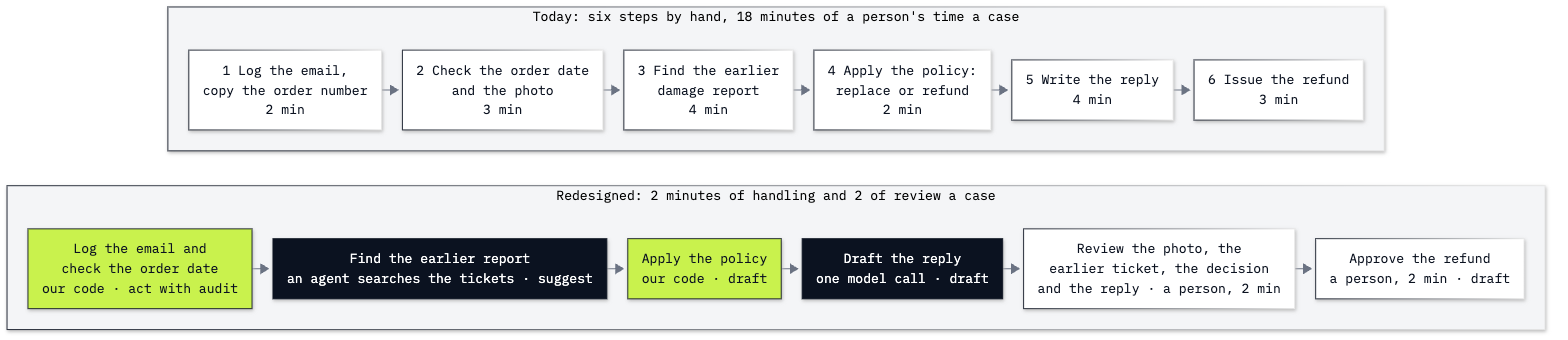

In [7]:
display(Image(filename=str(LAB / "resources" / "lab22_process_map.png"), width=760))

In the bottom row, lime boxes are our code, ink boxes are a model (an agent that searches the tickets, and one model
call that drafts the reply), and white boxes are people. Two steps done by hand become one step of our code, one
step goes to an agent, and a review step appears that the process did not have before. The parts that follow give
the reason for each of these.

**Checkpoint C.** Six steps, 18 minutes a case, and the evidence each step reads.

---

## Part D: Ask five questions of each step, and find the step that needs an agent

The lunch needed two questions. A process in a business needs five, because a redesign also has to be worth
building, and someone has to run it after it is built:

| Question | What a No means |
|---|---|
| Q1. Can we write its steps down? | what to do next depends on what the step finds: an agent may fit |
| Q2. Is its evidence written down where a tool can read it? | fix the record first, before automating anything |
| Q3. Can a mistake be undone at an acceptable cost? | a person approves before the step acts |
| Q4. Is the volume worth building for? | keep the work manual, or give people a checklist |
| Q5. Will someone own it in six months? | name an owner before building |

**Q1 is about the path:** who decides what happens next. **Q2 is about the evidence:** whether a tool can read what
the step needs. The two are separate questions. A step can have a known path and evidence no tool can reach, or
evidence that is easy to read and a path nobody can write down.

Q4 and Q5 have the same answer for every step of this process, so we answer them once. Our assumption is 300
damaged-media cases a month, and Part G works out whether that is enough volume to pay for the redesign. The support
operations lead owns the process. Q1 to Q3 change from step to step.

### Step 3, finding the earlier damage report, has no path we can write down

Five of the six steps have a path anyone can write down: copy a number, compare a date, apply a rule, fill in a
reply, pay an approved amount. Step 3 is different. Here is the ticket the shop wrote when this customer's first
copy arrived warped:

In [8]:
print((CORPUS / "ticket_06_germany_warped_vinyl.md").read_text())

# Ticket 06 — Germany, warped vinyl

Date: 2012-07-18
Customer: billing country Germany

Vinyl arrived warped. Customer sent a photo. Damaged-media policy: replace once at no charge.

Status: resolved. Replacement shipped 2012-07-20.



The ticket names neither the album nor the invoice. It has a date, a country and the word *vinyl*. Nothing in it names today's customer, so a rep cannot start from this ticket. They start from the customer: the customer's country, the damage tickets from that country, then the date on each ticket against the customer's invoices, until a ticket's date matches an invoice with a vinyl on it. For ticket 06 that means opening the customer's invoices from around 18 July 2012, finding the vinyl on them, and checking that it is the same title as today's. Another customer's earlier report might name the album and give no date,
and the search would go another way. What to open next depends on what the last record said, so Q1 is No for this
step. That is the kind of job an agent is for: a model chooses each next search from what the previous one returned.
This notebook does not build that agent, only decides where it belongs. An agent that searches these same tickets
with a search tool is built in Lab 13.

The evidence is all in the shop's records (Q2 Yes), and a wrong find is caught when a person reviews the decision
before any money moves (Q3 Yes).

Our answers for all six steps, in one dictionary. Each value is a tuple of three `True` or `False` answers, in the
order of the comment line:

In [9]:
answers = {
    #           Q1 steps written down, Q2 evidence a tool can read, Q3 a mistake can be undone cheaply
    "log":     (True,  True,  True),
    "check":   (True,  True,  True),
    "history": (False, True,  True),
    "decide":  (True,  True,  True),
    "reply":   (True,  True,  True),
    "refund":  (True,  True,  False),
}

Two answers are No. `history` has Q1 No, for the reason above. `refund` has Q3 No: a refund paid in error means
finance chasing the money back, and a confused customer.

Now a small function turns the three answers into a decision: the path (`workflow` or `agent`) and a list of what
has to happen first. We try it on the refund before we run it on every step.

In [10]:
def route(q1, q2, q3):
    path = "workflow" if q1 else "agent"
    needs = []
    if not q2:
        needs.append("fix the record first")
    if not q3:
        needs.append("a person approves")
    return path, needs


print(route(*answers["refund"]))

('workflow', ['a person approves'])


`route(*answers["refund"])` unpacks the tuple `(True, True, False)` into the three arguments `q1`, `q2` and `q3`.
The refund is a **workflow that needs a person's approval**: knowing every step of a payment does not give
software the right to make it. Now every step:

In [11]:
for step_id, step_answers in answers.items():
    path, needs = route(*step_answers)
    print(f"{step_id:8} {path:9} {', '.join(needs) or '-'}")

log      workflow  -
check    workflow  -
history  agent     -
decide   workflow  -
reply    workflow  -
refund   workflow  a person approves


Five workflows and **one agent**, `history`. The agent does only the part whose path we cannot write down. Once it
has found the earlier report, applying the policy (`decide`) is a rule our code runs. Writing the reply is a
workflow step too, even when one model call drafts the text: a model writing the words inside a fixed step does not
make that step an agent, because our code still decides what happens next.

**Checkpoint D.** Five workflows, one agent (`history`), and the refund needs a person's approval. You can say why
Q1 is No for `history` and Yes for `decide`.

---

## Part E: Set how far each step may go on its own

Part D decided who chooses the path. It did not decide how far each step may act before a person looks: that is the
autonomy level, with the same four levels as the lunch. We set it per step, with the reason written next to it.

In [12]:
autonomy = {
    "log":     ("act with audit", "our code logs the email, and the email itself is kept"),
    "check":   ("act with audit", "our code checks the date, and the photo goes to the review"),
    "history": ("suggest",        "the agent names the earlier ticket, and the reviewer opens it"),
    "decide":  ("draft",          "the decision waits for the review"),
    "reply":   ("draft",          "a reply that promises a refund cannot be taken back"),
    "refund":  ("draft",          "money leaves: finance approves every refund"),
}
for step_id, (level, reason) in autonomy.items():
    print(f"{step_id:8} {level:15} {reason}")

log      act with audit  our code logs the email, and the email itself is kept
check    act with audit  our code checks the date, and the photo goes to the review
history  suggest         the agent names the earlier ticket, and the reviewer opens it
decide   draft           the decision waits for the review
reply    draft           a reply that promises a refund cannot be taken back
refund   draft           money leaves: finance approves every refund


In the loop header, `(level, reason)` splits each value, a tuple of two strings, into its two parts.

Two steps act with audit, three are drafts, and the agent's step only suggests. The agent gets the least freedom of
any step, because the decision that depends on its find can move money. `decide` and `reply` answered Yes to Q3,
since a draft can be corrected, and they still stop at draft: the customer must not be promised a refund before a
person has agreed to it.

**Checkpoint E.** The refund is a workflow at draft, and the agent's step suggests. You can say why the refund stays
at draft though its path is known, and why the agent's step gets even less freedom.

---

## Part F: Redesign the refund and count its minutes

The answers so far say what software may do. A redesign also changes the work around it. Ours makes four changes,
all in the bottom row of the drawing in Part C:

1. **The copying goes.** Our code logs the email, reads the order number and checks the order date.
2. **The agent finds the earlier report,** and our code applies the policy to what it found.
3. **A review step is added.** A person reads the photo, the earlier ticket the agent named, the decision and the
   drafted reply together, and approves or corrects them. We assume 2 minutes.
4. **The refund stays with a person.** Finance gets the refund prepared and approves it: 2 minutes instead of 3.

In [13]:
# A person's minutes per case after the redesign
refund_after = {"log": 0, "check": 0, "history": 0, "decide": 0, "reply": 0, "refund": 2}
review = 2   # the new review step

handling = sum(refund_after.values())
print("Before:", refund_before, "min | after:", handling, "handling +", review, "review =", handling + review, "min")

Before: 18 min | after: 2 handling + 2 review = 4 min


On paper, **18 minutes become 4** a case. We keep review apart from handling because it is the number most likely
to be wrong. The read-back at lunch showed how a check a person adds can grow until it takes all the time the
handover saved. Part G puts a price on that.

**Checkpoint F.** 2 minutes of handling and 2 of review, 4 in all, against 18.

---

## Part G: Estimate what the redesign is worth each month, and raise the review time

A saving per case becomes a reason to build only when it is counted per month and set against what the system
costs. We count **minutes first**, then turn them into **dollars at a wage**, so a minute is never subtracted from a
dollar.

We write every assumption into one dictionary, `scenario`. None of them is a measurement: a pilot on real cases
would replace them.

In [14]:
scenario = {
    "cases_per_month": 300,
    "minutes_before": refund_before,   # 18
    "minutes_after": handling,         # 2
    "review_minutes": review,          # 2
    "rework_share": 0.10,              # one case in ten comes back ...
    "rework_minutes": 12,              # ... and takes 12 more minutes
    "wage_usd_per_hour": 30,
    "model_usd_per_case": 0.01,        # the agent's searches and the drafted reply
    "running_usd_per_month": 200,      # hosting, logs and the review queue
    "build_usd": 12_000,               # building it, once
    "build_months": 12,                # the build spread over a year
}

Three of these need a word:

- **Rework.** One case in ten comes back, because the agent named the wrong earlier ticket or the customer writes
  again, and a person spends 12 more minutes on it.
- **The model cost** is one number: 1 US cent a case. The agent's searches and the drafted reply take a handful of
  model calls, which cost a fraction of a cent on a small model. We round up on purpose, so the estimate does not
  look better than it is.
- **The build** is paid once. Dividing it by 12 spreads it over a year, so it can sit beside the monthly costs. It
  does not change when the money is paid.

First the arithmetic by hand, one line per idea:

In [15]:
s = scenario

# Minutes first
saved_per_case = s["minutes_before"] - s["minutes_after"] - s["review_minutes"] - s["rework_share"] * s["rework_minutes"]
freed_minutes = s["cases_per_month"] * saved_per_case

# Then dollars, at the wage
freed_value = freed_minutes / 60 * s["wage_usd_per_hour"]
model_cost = s["cases_per_month"] * s["model_usd_per_case"]
system_cost = model_cost + s["running_usd_per_month"] + s["build_usd"] / s["build_months"]

print(f"Saved per case: {saved_per_case:.1f} min | freed a month: {freed_minutes:,.0f} min ({freed_minutes / 60:.0f} hours)")
print(f"Those hours are worth {freed_value:,.0f} USD at {s['wage_usd_per_hour']} USD an hour")
print(f"System cost: {system_cost:,.0f} USD a month, of which the model calls are {model_cost:,.0f} USD")
print(f"Net: {freed_value - system_cost:+,.0f} USD a month")

Saved per case: 12.8 min | freed a month: 3,840 min (64 hours)
Those hours are worth 1,920 USD at 30 USD an hour
System cost: 1,203 USD a month, of which the model calls are 3 USD
Net: +717 USD a month


Read it from the top. Each case saves 18 − 2 − 2 − 0.1 × 12 = **12.8 minutes**. Over 300 cases that frees **3,840
minutes**, 64 hours, worth **1,920 US dollars** at 30 dollars an hour. The system costs **1,203 dollars** a month:
1,000 for the build, 200 for running it, and **3 for the model calls**. People's minutes and the build decide the
result. The model calls, 3 dollars of 1,203, are too small to change it. Net: **717 dollars a month** in favour of
the redesign.

**Important:** the freed hours become money saved only if someone changes what those people do with them. Until
then, 1,920 dollars is what the time is worth, not a cut in the payroll. The estimate also leaves out what a wrong
refund costs, which is what the review is there to prevent.

Now the same arithmetic as a function, so we can change one assumption and recompute everything that depends on it:

In [16]:
def estimate(s):
    saved_per_case = s["minutes_before"] - s["minutes_after"] - s["review_minutes"] - s["rework_share"] * s["rework_minutes"]
    freed_minutes = s["cases_per_month"] * saved_per_case
    freed_value = freed_minutes / 60 * s["wage_usd_per_hour"]
    system_cost = (s["cases_per_month"] * s["model_usd_per_case"] + s["running_usd_per_month"]
                   + s["build_usd"] / s["build_months"])
    return freed_minutes, freed_value - system_cost


print(estimate(scenario))

(3840.0, 717.0)


The same two numbers, 3,840 minutes freed and 717 dollars net. `estimate` returns a tuple: the freed minutes first,
the net dollars second.

### When the reviewer re-checks the agent's search

Think back to the read-back at lunch. In the first weeks, the reviewer does not trust the agent's find and opens the
customer's past tickets to check it. That adds the 4 minutes the search took by hand, and 2 more to read the tickets
the search turns up, to the 2-minute review: 8 minutes a case. `scenario.copy()` gives a separate dictionary, so the
base scenario stays as it is.

Before you run it, guess: does the redesign still free time, and is it still worth its cost?

In [17]:
careful = scenario.copy()
careful["review_minutes"] = 8

freed_minutes, net = estimate(careful)
print(f"Review 8 min: {freed_minutes:,.0f} minutes freed a month ({freed_minutes / 60:.0f} hours), net {net:+,.0f} USD a month")

Review 8 min: 2,040 minutes freed a month (34 hours), net -183 USD a month


The redesign still frees **2,040 minutes a month**, 34 hours of a person's time, and **loses 183 dollars a month**:
those hours are worth 1,020 dollars, less than the 1,203 the system costs. The model cost did not move. The review
did: six more minutes on each of 300 cases is 1,800 minutes, worth 900 dollars, more than the 717 the design made
before.

That answers Q4 for this process: at 300 cases a month, the redesign pays only while the review stays short. The ways
to keep it short are changes to the process again, as at lunch. The agent can return the ticket id and the lines it
matched, so the reviewer reads one ticket instead of searching again. Or only the cases where the agent found no
earlier report, or more than one, go to a full check.

**Checkpoint G.** The base scenario frees 3,840 minutes and makes +717 dollars a month. With 8 minutes of review it
frees 2,040 minutes and makes −183 dollars a month. You can say why freeing a person's time is not, on its own, a
reason to build.

---

## What you can do now

- Write a process down as steps, with the minutes a person spends on each and the evidence each one reads (Parts A
  and C).
- Ask five questions of each step, and tell a workflow step from a step where an agent fits (Part D).
- Set an autonomy level per step with a reason, and keep a payment at draft even when every step of it is known
  (Parts A and E).
- Count a redesign's minutes with the review it adds (Parts B and F), and see a person's check take the whole saving
  at lunch and turn the refund's net negative (Parts B and G).
- Turn freed minutes into dollars at a wage, set them against the system's costs, and change one assumption to see
  what moves (Part G).

## Going further

- **Your own process.** Write its steps into a list like `refund_steps`, answer Q1 to Q3 for each step in a dictionary
  like `answers`, run `route`, and copy `scenario` with your own volume, minutes and costs. Keep customers' personal
  data out of it. Deciding that a process should stay manual is a complete answer when the reasons support it.
- **Build, buy or neither.** Whether to build this redesign, buy a support platform that does part of it, or leave
  the work manual is the last question of Lab 23
  ([Part G of its guide](../23_Agent_Platforms/GUIDE.md#part-g-decide-build-buy-or-neither)). Part G chooses "neither" for the reasons Q2, Q4 and Q5 test here: the data the step needs is not available, the volume is too low, or nobody owns the result.
- **Measure before you commit.** Every number in `scenario` is ours. A pilot of a few weeks would time handling,
  review and rework on real cases, and count the wrong refunds the review caught.
- **What the estimate leaves out:** the cost of a wrong refund paid out, a customer's harm when a reply is wrong, and
  the time cases wait in the review queue.

## Challenge

The worked answers are in
[`solved/22_process_reengineering_solution.ipynb`](solved/22_process_reengineering_solution.ipynb), which runs on
its own.

1. **Read back only the orders that need it.** At lunch, 3 of the 12 orders have an allergy or a comment, and the
   organiser reads back only those three. How many minutes of the organiser's Friday does lunch take now? Expected:
   4 minutes (1 for the payment and 3 for the read-back), against 12 before the handover.
2. **The photo is missing.** A customer writes without a photo of the damage. Copy the `check` step's answers with
   Q2 set to `False` and run `route` on them. Expected: `('workflow', ['fix the record first'])`. The path is still
   known, so the step stays a workflow, and its first job is to ask the customer for the photo before anything is
   decided.
3. **Find where the redesign stops paying.** Run `estimate` with review times from 2 to 10 minutes and print the net
   for each. Expected: the net falls by 150 dollars for every extra minute of review, and turns negative between 6
   minutes (+117 dollars) and 7 minutes (−33 dollars).

Add your answers below this cell.

## Resources

- [Python tutorial: data structures](https://docs.python.org/3/tutorial/datastructures.html): lists, tuples and
  dictionaries, and looping over a dictionary with `.items()`.
- [Python tutorial: unpacking argument lists](https://docs.python.org/3/tutorial/controlflow.html#unpacking-argument-lists):
  what the `*` in `route(*answers["refund"])` does.
- [Anthropic: Building effective agents](https://www.anthropic.com/research/building-effective-agents): workflows
  (predefined code paths) against agents (the model directs its own steps), and when each fits.
- [OpenAI: A practical guide to building agents](https://cdn.openai.com/business-guides-and-resources/a-practical-guide-to-building-agents.pdf):
  the section "When should you build an agent?" names complex decisions, rules that are hard to maintain and
  unstructured data as the cases where a fixed solution falls short.

Next: [Lab 23: What agent platforms sell](../23_Agent_Platforms/README.md). Back to [the lab list](../README.md).